# 03 — Previsão de inadimplência

Comparação entre regressão logística e Random Forest para prever inadimplência no mês seguinte. A escolha do modelo e do limiar é feita no treino; o teste fica reservado para a avaliação final.

**Base:** UCI Default of Credit Card Clients (id 350).

## 1. Configuração

Mesma fonte de dados, mesma semente e mesma separação usada no notebook 02.

In [1]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    f1_score, fbeta_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score
)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from ucimlrepo import fetch_ucirepo

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
(ROOT / "models").mkdir(parents=True, exist_ok=True)
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
(ROOT / "data" / "processed").mkdir(parents=True, exist_ok=True)

## 2. Dados e separação

Repetimos o primeiro fold do `StratifiedGroupKFold` do notebook 02. Perfis de entrada idênticos não são divididos entre treino e teste.

In [2]:
colunas = {
    "X1": "LIMIT_BAL", "X2": "SEX", "X3": "EDUCATION",
    "X4": "MARRIAGE", "X5": "AGE", "X6": "PAY_0",
    "X7": "PAY_2", "X8": "PAY_3", "X9": "PAY_4",
    "X10": "PAY_5", "X11": "PAY_6", "X12": "BILL_AMT1",
    "X13": "BILL_AMT2", "X14": "BILL_AMT3", "X15": "BILL_AMT4",
    "X16": "BILL_AMT5", "X17": "BILL_AMT6", "X18": "PAY_AMT1",
    "X19": "PAY_AMT2", "X20": "PAY_AMT3", "X21": "PAY_AMT4",
    "X22": "PAY_AMT5", "X23": "PAY_AMT6"
}

dataset = fetch_ucirepo(id=350)
X = dataset.data.features.rename(columns=colunas).drop(columns="ID", errors="ignore").copy()
y = dataset.data.targets.iloc[:, 0].rename("inadimplente").astype(int)

grupos = pd.util.hash_pandas_object(X, index=False)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_treino, idx_teste = next(splitter.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_treino].copy(), X.iloc[idx_teste].copy()
y_train, y_test = y.iloc[idx_treino].copy(), y.iloc[idx_teste].copy()
grupos_treino = grupos.iloc[idx_treino]

assert set(grupos.iloc[idx_treino]).isdisjoint(set(grupos.iloc[idx_teste]))
assert X_train.index.intersection(X_test.index).empty
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Inadimplência (treino):", f"{y_train.mean():.2%}")
print("Inadimplência (teste):", f"{y_test.mean():.2%}")

Treino: (24000, 23) | Teste: (6000, 23)
Inadimplência (treino): 22.12%
Inadimplência (teste): 22.12%


## 3. Variáveis e modelos

Nesta primeira versão usamos apenas limite, faturas, valores pagos e histórico de atrasos. As variáveis demográficas ficam fora dos preditores e serão retomadas na análise de vieses.

As transformações ficam dentro do pipeline para serem ajustadas separadamente em cada fold.

In [3]:
status = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
financeiras = ["LIMIT_BAL"] + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]
features = status + financeiras

X_train_model = X_train[features].copy()
X_test_model = X_test[features].copy()

# arcsinh comporta valores negativos e reduz a assimetria dos valores monetários.
preprocessamento = ColumnTransformer([
    ("financeiras", Pipeline([
        ("transformacao", FunctionTransformer(np.arcsinh, validate=False)),
        ("escala", StandardScaler())
    ]), financeiras),
    ("status", StandardScaler(), status)
])

modelos = {
    "Regressão logística": Pipeline([
        ("preprocessamento", preprocessamento),
        ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("preprocessamento", preprocessamento),
        ("modelo", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}
print("Variáveis utilizadas:", len(features))

Variáveis utilizadas: 19


## 4. Validação cruzada no treino

Geramos probabilidades fora da amostra para cada cliente do treino (*out-of-fold*). A métrica principal será PR-AUC (average precision), acompanhada de ROC-AUC, precision, recall e F1 no limiar de 0,50. Os modelos usam pesos de classe, sem reamostragem.

In [4]:
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
resultados = []
probabilidades_cv = {}

for nome, pipeline in modelos.items():
    print("Validando:", nome)
    proba = cross_val_predict(
        pipeline, X_train_model, y_train,
        cv=cv, groups=grupos_treino,
        method="predict_proba", n_jobs=1
    )[:, 1]
    probabilidades_cv[nome] = proba
    classe = (proba >= 0.50).astype(int)
    resultados.append({
        "modelo": nome,
        "PR-AUC": average_precision_score(y_train, proba),
        "ROC-AUC": roc_auc_score(y_train, proba),
        "precision": precision_score(y_train, classe, zero_division=0),
        "recall": recall_score(y_train, classe, zero_division=0),
        "F1": f1_score(y_train, classe, zero_division=0)
    })

comparacao_cv = pd.DataFrame(resultados).set_index("modelo")
display(comparacao_cv.round(3))

Validando: Regressão logística
Validando: Random Forest


,PR-AUC,ROC-AUC,precision,recall,F1
modelo,,,,,
Regressão logística,0.497,0.745,0.434,0.617,0.510
Random Forest,0.547,0.771,0.557,0.522,0.539


## 5. Escolha do modelo

Selecionamos o modelo com maior PR-AUC no treino. Não olhamos o desempenho do teste para decidir.

Modelo selecionado: Random Forest
PR-AUC no treino: 0.547


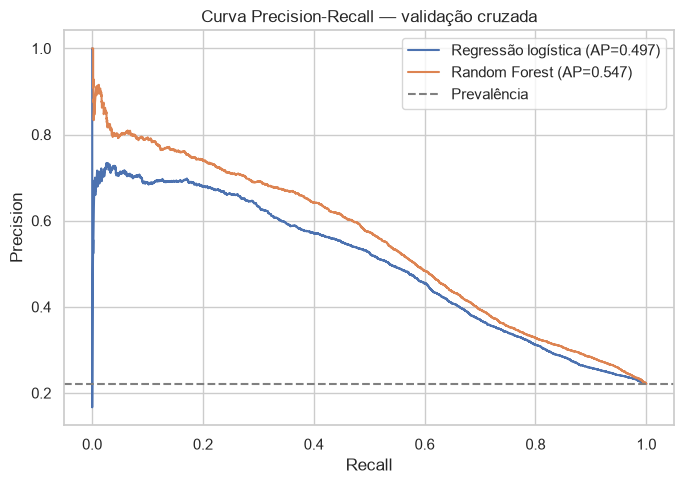

In [5]:
modelo_escolhido = comparacao_cv["PR-AUC"].idxmax()
proba_cv = probabilidades_cv[modelo_escolhido]

print("Modelo selecionado:", modelo_escolhido)
print("PR-AUC no treino:", round(comparacao_cv.loc[modelo_escolhido, "PR-AUC"], 3))

fig, ax = plt.subplots(figsize=(7, 5))
for nome, proba in probabilidades_cv.items():
    precision, recall, _ = precision_recall_curve(y_train, proba)
    ax.plot(recall, precision, label=f"{nome} (AP={average_precision_score(y_train, proba):.3f})")
ax.axhline(y_train.mean(), linestyle="--", color="gray", label="Prevalência")
ax.set(xlabel="Recall", ylabel="Precision", title="Curva Precision-Recall — validação cruzada")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "03_precision_recall_cv.png", dpi=140)
plt.show()

## 6. Ajuste do limiar

Testamos limiares nas probabilidades da validação cruzada. Como deixar de identificar um inadimplente pode ter custo relevante, usamos F2 nesta simulação, dando mais peso ao recall. É uma escolha de projeto, não uma política de crédito validada.

Limiar definido no treino: 0.19


,limiar,precision,recall,F1,F2
9,0.19,0.293,0.880,0.439,0.628
11,0.21,0.307,0.848,0.451,0.627
10,0.20,0.299,0.863,0.444,0.627
8,0.18,0.285,0.892,0.432,0.626
7,0.17,0.279,0.908,0.427,0.626


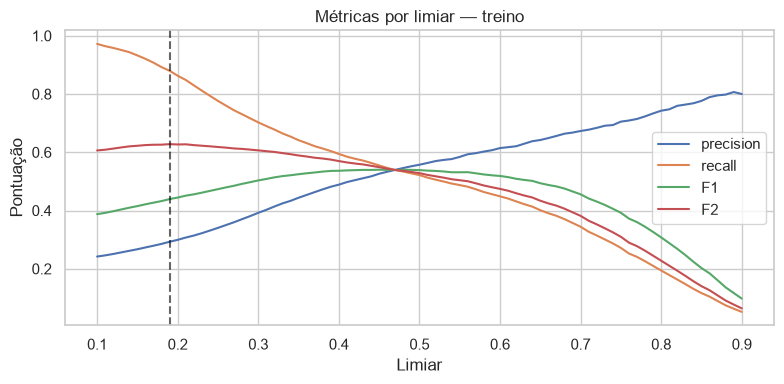

In [6]:
limiares = np.round(np.arange(0.10, 0.91, 0.01), 2)
metricas_limiares = []

for limiar in limiares:
    previsao = (proba_cv >= limiar).astype(int)
    metricas_limiares.append({
        "limiar": limiar,
        "precision": precision_score(y_train, previsao, zero_division=0),
        "recall": recall_score(y_train, previsao, zero_division=0),
        "F1": f1_score(y_train, previsao, zero_division=0),
        "F2": fbeta_score(y_train, previsao, beta=2, zero_division=0)
    })

avaliacao_limiares = pd.DataFrame(metricas_limiares)
limiar_escolhido = float(avaliacao_limiares.loc[avaliacao_limiares["F2"].idxmax(), "limiar"])
print("Limiar definido no treino:", limiar_escolhido)
display(avaliacao_limiares.sort_values("F2", ascending=False).head(5).round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for metrica in ["precision", "recall", "F1", "F2"]:
    ax.plot(avaliacao_limiares["limiar"], avaliacao_limiares[metrica], label=metrica)
ax.axvline(limiar_escolhido, linestyle="--", color="black", alpha=0.6)
ax.set(xlabel="Limiar", ylabel="Pontuação", title="Métricas por limiar — treino")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "03_limiares_cv.png", dpi=140)
plt.show()

## 7. Avaliação final no teste

Treinamos o modelo escolhido em todo o conjunto de treino e avaliamos uma única vez no teste reservado. Exibimos os resultados para 0,50 e para o limiar definido anteriormente.

PR-AUC no teste: 0.537
ROC-AUC no teste: 0.775

Limiar 0.50
              precision    recall  f1-score   support

           0      0.859     0.878     0.869      4673
           1      0.536     0.494     0.514      1327

    accuracy                          0.793      6000
   macro avg      0.697     0.686     0.691      6000
weighted avg      0.788     0.793     0.790      6000


Limiar 0.19
              precision    recall  f1-score   support

           0      0.923     0.398     0.556      4673
           1      0.294     0.883     0.441      1327

    accuracy                          0.505      6000
   macro avg      0.609     0.641     0.499      6000
weighted avg      0.784     0.505     0.531      6000



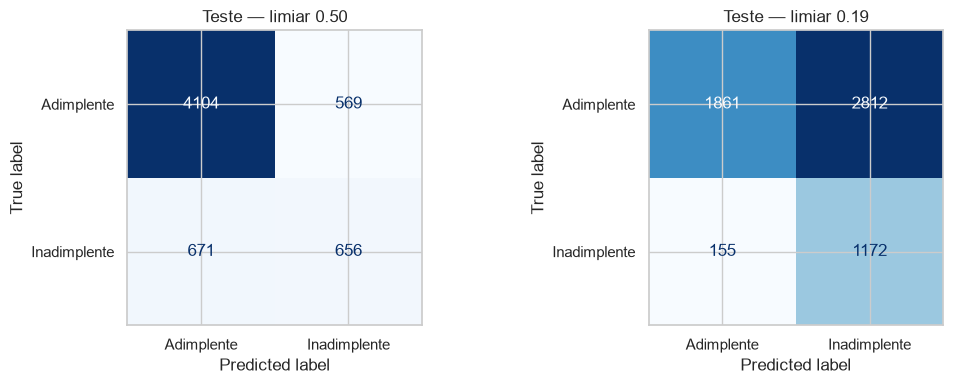

In [7]:
modelo_final = modelos[modelo_escolhido]
modelo_final.fit(X_train_model, y_train)
proba_teste = modelo_final.predict_proba(X_test_model)[:, 1]

print("PR-AUC no teste:", round(average_precision_score(y_test, proba_teste), 3))
print("ROC-AUC no teste:", round(roc_auc_score(y_test, proba_teste), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, limiar in zip(axes, [0.50, limiar_escolhido]):
    pred = (proba_teste >= limiar).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Adimplente", "Inadimplente"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(f"Teste — limiar {limiar:.2f}")
    print(f"\nLimiar {limiar:.2f}")
    print(classification_report(y_test, pred, digits=3, zero_division=0))
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "03_matriz_confusao.png", dpi=140)
plt.show()

## 8. Comparação entre treino e teste

Diferenças grandes entre desempenho fora da amostra no treino e no teste merecem investigação. Esta comparação não substitui curvas de aprendizado, que podem ser incluídas no refinamento.

In [8]:
resumo_generalizacao = pd.DataFrame({
    "conjunto": ["CV (treino)", "Teste"],
    "PR-AUC": [average_precision_score(y_train, proba_cv), average_precision_score(y_test, proba_teste)],
    "ROC-AUC": [roc_auc_score(y_train, proba_cv), roc_auc_score(y_test, proba_teste)],
    "F1": [
        f1_score(y_train, proba_cv >= limiar_escolhido),
        f1_score(y_test, proba_teste >= limiar_escolhido)
    ],
    "recall": [
        recall_score(y_train, proba_cv >= limiar_escolhido),
        recall_score(y_test, proba_teste >= limiar_escolhido)
    ]
})
display(resumo_generalizacao.round(3))

,conjunto,PR-AUC,ROC-AUC,F1,recall
0,CV (treino),0.547,0.771,0.439,0.880
1,Teste,0.537,0.775,0.441,0.883


## 9. Exportação

Salvamos o pipeline completo, os metadados e as probabilidades de teste. O arquivo de teste será usado na análise de vieses. Não usaremos seus rótulos para reajustar o modelo ou o limiar.

In [9]:
arquivo_modelo = ROOT / "models" / "classificador_inadimplencia.joblib"
joblib.dump(modelo_final, arquivo_modelo)

metadados = {
    "dataset": "UCI Default of Credit Card Clients (id=350)",
    "modelo": modelo_escolhido,
    "limiar": limiar_escolhido,
    "features": features,
    "random_state": RANDOM_STATE,
    "split": "primeiro fold StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)",
    "selecao": "PR-AUC em probabilidades out-of-fold no treino",
    "ajuste_limiar": "maior F2 out-of-fold no treino"
}
(ROOT / "models" / "classificacao_metadata.json").write_text(
    json.dumps(metadados, indent=2, ensure_ascii=False), encoding="utf-8"
)

predicoes_teste = X_test[["SEX", "AGE", "EDUCATION", "MARRIAGE"]].copy()
predicoes_teste["inadimplente"] = y_test
predicoes_teste["probabilidade"] = proba_teste
predicoes_teste["predito"] = (proba_teste >= limiar_escolhido).astype(int)
predicoes_teste.rename_axis("row_id").to_csv(
    ROOT / "data" / "processed" / "predicoes_teste.csv"
)
print("Arquivos salvos:", arquivo_modelo.name, "e predicoes_teste.csv")

Arquivos salvos: classificador_inadimplencia.joblib e predicoes_teste.csv


## 10. Conclusão

O Random Forest teve o melhor resultado na validação cruzada, com **PR-AUC de 0,547**, contra **0,497** da regressão logística. No conjunto de teste, obteve **PR-AUC de 0,537** e **ROC-AUC de 0,775**.

Com o limiar padrão de **0,50**, a classe inadimplente apresentou precision de **0,536**, recall de **0,494** e F1 de **0,514**. O limiar de **0,19**, escolhido pelo maior F2 na validação cruzada, aumentou o recall para **0,883**, mas reduziu a precision para **0,294** e o F1 para **0,441**. Portanto, o ajuste prioriza identificar mais inadimplentes e aumenta a quantidade de falsos alertas.

Os resultados da validação cruzada e do teste foram próximos (PR-AUC de **0,547** e **0,537**). Isso indica estabilidade inicial nesta divisão, mas não é suficiente para garantir desempenho em produção.

**Limitações:** dados históricos de Taiwan de 2005, avaliação sem validação temporal, sem estudo de calibração das probabilidades e sem análise de custo financeiro de falsos positivos e falsos negativos. O limiar escolhido é experimental e não constitui regra de concessão de crédito.

**Próxima etapa:** regressão para estimar uma variável financeira futura e avaliação com MAE/RMSE.